# Human lymph node

Integrate multimodal inputs with MELON, identify spatial domains, and visualize the tissue.

The functions show the computation at each stage. The following cells continue from the supplied intermediate files, so training and clustering are not repeated. Start with prepared modality features; see the [Tutorials](https://txbrook.github.io/MELON_website/tutorials/) for preprocessing.

In [1]:
from pathlib import Path
import os, sys
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
sys.path.insert(0, str(repo / "Reproduce"))
from _shared.paper_plots import *
from _shared.workflow import assay_shape, align_partition
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "02_Human_lymph_node"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."

## 1. Assemble the multimodal inputs

RNA and protein share 3,484 spatial barcodes. The files below identify the assay inputs. Normalization is handled in the preprocessing workflow; its runtime arrays are not separately included in this archive.

In [2]:
input_paths = {'RNA': '01_source_data/adata_RNA.h5ad', 'Protein': '01_source_data/adata_ADT.h5ad'}
input_paths = {name: DATA / path for name, path in input_paths.items()}
coords = read_indexed(DATA / "01_source_data/coords.csv")[["x", "y"]]
input_shapes = {name: assay_shape(path) for name, path in input_paths.items()}
assert all(shape[0] == len(coords) for shape in input_shapes.values())
display(input_shapes)

{'RNA': (3484, 18085), 'Protein': (3484, 31)}

## 2. Configure and train MELON

The model combines modality-specific encoders with spatial attention and contrastive representation learning. The configuration cell below contains the manuscript-default settings and can be edited directly. The original numerical training seed is not recorded with this embedding; the configured seed is the package default.

Model construction and embedding export use the [MELON implementation](../_shared/engine.py). `integrate_modalities` takes prepared feature arrays in the modality order above, together with their aligned coordinates.

In [3]:
# Edit the parameters here.
config = {
    'epochs': 100,
    'batch_size': 2048,
    'embed_dim': 128,
    'training_seed': 2027,
    'learning_rate': 0.001,
    'weight_decay': 1e-05,
    'temperature': 0.1,
    'training_spatial_k': 16,
    'export_spatial_k': 16,
    'augment_p': 0.8,
    'augmentations': ['gaussian_noise', 'feature_dropout', 'neighbor_mix'],
    'shuffle_batches': False,
    'historical_five_modal': False,
    'clustering_seed': 2025,
    'target_clusters': 10,
    'clustering_neighbors': 10,
    'leiden_resolution': 1.0,
}

In [4]:
def integrate_modalities(features, coordinates, config):
    """Learn a joint representation from aligned, preprocessed modality arrays."""
    import torch
    import pytorch_lightning as pl
    from _shared.engine import make_model, export_embedding, PaperAugmentations
    from _shared.publication_model.data import DualAugDataModule, SpatialOmicsAugmentations
    from _shared.publication_model.utils import build_knn_mask

    pl.seed_everything(config["training_seed"], workers=True)
    tensors = [torch.as_tensor(x, dtype=torch.float32) for x in features]
    xy = torch.as_tensor(coordinates.to_numpy(), dtype=torch.float32)
    mask, weight = build_knn_mask(xy, k=config["training_spatial_k"],
                                  include_self=True, return_weights=True)
    augmentation = SpatialOmicsAugmentations if config["historical_five_modal"] else PaperAugmentations
    aug = dict(augmentations=config.get("augmentations", ["gaussian_noise", "feature_dropout", "neighbor_mix"]),
               p=config["augment_p"])
    data = DualAugDataModule(
        mods_raw=tensors, coords=xy, neighbor_mask=mask, neighbor_weight=weight,
        batch_size=config["batch_size"], augmentA=augmentation(**aug), augmentB=augmentation(**aug),
        spot_tokenization=True, shuffle=config["shuffle_batches"])
    model = make_model([x.shape[1] for x in features], config)
    trainer = pl.Trainer(max_epochs=config["epochs"], accelerator="cpu", devices=1,
                         logger=False, enable_checkpointing=False, deterministic=True)
    trainer.fit(model, datamodule=data)
    z = export_embedding(model, tensors, xy, config["export_spatial_k"])
    return pd.DataFrame(z, index=coordinates.index)

The output of this stage is one joint embedding vector per spatial barcode. Continue from that intermediate representation below.

In [5]:
# Continue at the joint-representation node produced by MELON.
embedding = read_indexed(DATA / "03_embeddings/MELON.csv")
embedding = align_embedding(embedding, coords)
display({"spots": len(embedding), "embedding_dimensions": embedding.shape[1]})

{'spots': 3484, 'embedding_dimensions': 128}

## 3. Identify spatial domains

Construct a neighbor graph from the joint representation and identify 10 spatial domains using the repository’s Leiden procedure, including its target-count handling. The partition node supplies the assignments for the next step.

In [6]:
def identify_domains(embedding):
    from melon_pkg.cli_cluster import leiden_clustering
    labels = leiden_clustering(embedding.to_numpy(), n_clusters=config["target_clusters"], n_neighbors=config["clustering_neighbors"],
                                seed=config["clustering_seed"], resolution=config["leiden_resolution"])
    return pd.Series(labels, index=embedding.index, name="MELON")

domains = align_partition(DATA / "04_clusters/final_clusters.csv", embedding)
display({"spatial_domains": domains.nunique()})

{'spatial_domains': 10}

## 4. Map domains onto the tissue

Join domain assignments to spatial coordinates by barcode. Each point represents one spot.

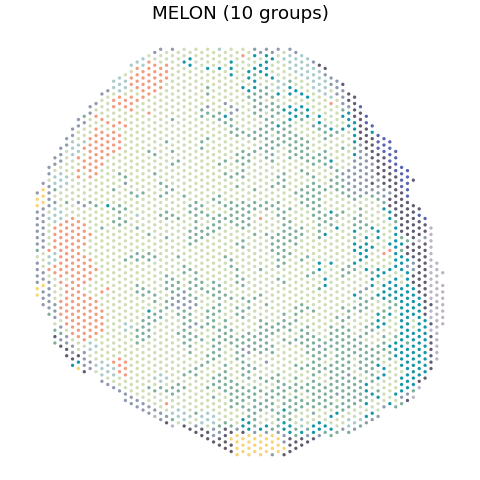

In [7]:
plot_data = coords.loc[embedding.index].copy()
plot_data["MELON"] = domains
fig = spatial_panels(plot_data, ["MELON"], ncols=1)
fig.set_size_inches(4, 4)
ax = fig.axes[0]
ax.set_aspect("auto")
ax.set_box_aspect(1)
show(fig, crop=False)